In [4]:
print("Version de NumPy :", np.__version__)

Version de NumPy : 2.4.6


In [2]:
import numpy as np 

In [6]:
#chargement des donnnées et affichage des 3 premières lignes 
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
print("Noms des colonnes: ", d.dtype.names)
print("Trois premières lignes du tableau :", d[:3])

Noms des colonnes:  ('date', 'mois', 'jour', 'temp_max_c', 'temp_min_c', 'humidite_pct', 'pluie_mm', 'vent_kmh')
Trois premières lignes du tableau : [('2025-01-01', 1, 1, 27.1, 18.8, 66, 0., 16)
 ('2025-01-02', 1, 2, 26.7, 20.3, 63, 0., 13)
 ('2025-01-03', 1, 3, 26. , 18. , 66, 0., 22)]


In [8]:
#Extractions des colonnes 
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", 
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])

print("Exemple d'extraction - 5 premières températures max :", tmax[:5])

Exemple d'extraction - 5 premières températures max : [27.1 26.7 26.  26.  27.9]


Explication
Le tableau structuré diffère d'un tableau classique de Numpy car il peut contenir des éléments de types différents alors qu'un tableau numpy classique ne peut contenir que des éléments de types similaires/identiques. 

Partie 2

In [16]:
#affichage forme, nombre de dimensions et types des colonnes
print("Forme de tmax: ", tmax.shape , " | Nombre de dimensions de tmax: ", tmax.ndim, " | Type de colonnes de tmax: ", tmax.dtype) 
print("Forme de mois: ", mois.shape , " | Nombre de dimensions de mois: ", mois.ndim, " | Type de colonnes de mois: ", mois.dtype) 
print("Forme de dates: ", dates.shape , " | Nombre de dimensions de dates: ", dates.ndim, " | Type de colonnes de dates: ", dates.dtype) 

Forme de tmax:  (365,)  | Nombre de dimensions de tmax:  1  | Type de colonnes de tmax:  float64
Forme de mois:  (365,)  | Nombre de dimensions de mois:  1  | Type de colonnes de mois:  int64
Forme de dates:  (365,)  | Nombre de dimensions de dates:  1  | Type de colonnes de dates:  <U10


In [20]:
#affichage de la température max la plus haute et la plus basse de l'année 
print("La température la plus haute: ", np.max(tmax))
print("La température la plus basse: ", np.min(tmax))

La température la plus haute:  34.1
La température la plus basse:  22.4


In [37]:
#affichage moyenne de tmax et tmin à deux décimales
moy_tmin = np.mean(tmin)
print(f"Moyenne annuelle de tmin: {moy_tmin:.2f}")
moy_tmax = np.mean(tmax)
print(f"Moyenne annuelle de tmax: {moy_tmax:.2f}")

Moyenne annuelle de tmin: 21.77
Moyenne annuelle de tmax: 28.01


In [38]:
# Températures maximales de la première semaine de janvier (7 premiers jours)
tmax_1ere_sem_jan = tmax[:7]

#Températures maximales des 10 derniers jours de l'année
tmax_10_dernier_jours = tmax[-10:]

# data du 15 mars
masque_15_mars = (dates == "2025-03-15")
date_15m = dates[masque_15_mars][0]
tmax_15m = tmax[masque_15_mars][0]
tmin_15m = tmin[masque_15_mars][0]
pluie_15m = pluie[masque_15_mars][0]

# Températures maximales d'un jour sur sept à partir du 1er janvier
tmax_1_sur_7 = tmax[::7]

print("1. Tmax 1ère semaine de janvier :", tmax_1ere_sem_jan)
print("2. Tmax 10 derniers jours :", tmax_10_dernier_jours)
print(f"3. Données du 15 mars -> Date: {date_15m}, Tmax: {tmax_15m}°C, Tmin: {tmin_15m}°C, Pluie: {pluie_15m}mm")
print("4. Tmax 1 jour sur 7 (premières valeurs) :", tmax_1_sur_7[:5])

1. Tmax 1ère semaine de janvier : [27.1 26.7 26.  26.  27.9 27.1 24.6]
2. Tmax 10 derniers jours : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]
3. Données du 15 mars -> Date: 2025-03-15, Tmax: 26.4°C, Tmin: 19.1°C, Pluie: 0.0mm
4. Tmax 1 jour sur 7 (premières valeurs) : [27.1 26.1 24.8 25.  23.5]


In [39]:
idx_plus_chaud = np.argmax(tmax)
idx_plus_frais = np.argmin(tmin)

date_plus_chaude = dates[idx_plus_chaud]
tmax_pic = tmax[idx_plus_chaud]

date_plus_fraiche = dates[idx_plus_frais]
tmin_creux = tmin[idx_plus_frais]

print(f"Journée la plus chaude : {date_plus_chaude} avec {tmax_pic}°C (tmax)")
print(f"Nuit la plus fraîche   : {date_plus_fraiche} avec {tmin_creux}°C (tmin)")

Journée la plus chaude : 2025-09-18 avec 34.1°C (tmax)
Nuit la plus fraîche   : 2025-02-07 avec 16.1°C (tmin)


In [40]:
# Masque booléen pour le mois d'août (mois 8)
masque_aout = (mois == 8)
moy_tmax_aout = np.mean(tmax[masque_aout])

print(f"Moyenne de tmax en août : {moy_tmax_aout:.2f}°C")

Moyenne de tmax en août : 30.22°C


In [41]:
# Calcul vectorisé sans boucle
nb_jours = np.bincount(mois - 1)                 # Nombre de jours par mois
somme = np.bincount(mois - 1, weights=tmax)     # Somme de tmax par mois
moy_tmax = somme / nb_jours                      # Moyenne mensuelle

# Affichage des résultats côte à côte
for nom, moy in zip(NOMS_MOIS, moy_tmax):
    print(f"{nom:>5} : {moy:.2f}°C")

  Jan : 25.29°C
  Fév : 25.85°C
  Mar : 26.36°C
  Avr : 26.57°C
  Mai : 26.64°C
 Juin : 29.23°C
 Juil : 28.47°C
 Août : 30.22°C
  Sep : 30.88°C
  Oct : 31.20°C
  Nov : 28.48°C
  Déc : 26.87°C


Mois le plus chaud et le plus frais en moyenne

In [42]:
idx_mois_chaud = np.argmax(moy_tmax)
idx_mois_frais = np.argmin(moy_tmax)

mois_plus_chaud = NOMS_MOIS[idx_mois_chaud]
temp_max_moy_chaud = moy_tmax[idx_mois_chaud]

mois_plus_frais = NOMS_MOIS[idx_mois_frais]
temp_max_moy_frais = moy_tmax[idx_mois_frais]

print(f"Mois le plus chaud en moyenne : {mois_plus_chaud} ({temp_max_moy_chaud:.2f}°C)")
print(f"Mois le plus frais en moyenne : {mois_plus_frais} ({temp_max_moy_frais:.2f}°C)")

Mois le plus chaud en moyenne : Oct (31.20°C)
Mois le plus frais en moyenne : Jan (25.29°C)


Amplitude thermique journalière et mensuelle

In [43]:
# Amplitude journalière (tmax - tmin)
amplitude = tmax - tmin

# Maximum et moyenne par mois avec np.bincount
amp_max_mois = np.bincount(mois - 1, weights=amplitude) / nb_jours # Note : calcul de la moyenne
amp_pic_mois = np.array([np.max(amplitude[mois == m]) for m in range(1, 13)]) # Maximum absolu par mois

moy_amp_mensuelle = np.bincount(mois - 1, weights=amplitude) / nb_jours

idx_amp_faible = np.argmin(moy_amp_mensuelle)
mois_amp_faible = NOMS_MOIS[idx_amp_faible]

print("Moyenne de l'amplitude thermique par mois :")
for nom, amp in zip(NOMS_MOIS, moy_amp_mensuelle):
    print(f"{nom:>5} : {amp:.2f}°C")

print(f"\nSaison / Mois où l'amplitude est la plus faible : {mois_amp_faible} ({moy_amp_mensuelle[idx_amp_faible]:.2f}°C)")

Moyenne de l'amplitude thermique par mois :
  Jan : 7.10°C
  Fév : 7.97°C
  Mar : 7.17°C
  Avr : 6.89°C
  Mai : 5.85°C
 Juin : 5.46°C
 Juil : 4.33°C
 Août : 4.68°C
  Sep : 5.62°C
  Oct : 6.19°C
  Nov : 6.62°C
  Déc : 7.23°C

Saison / Mois où l'amplitude est la plus faible : Juil (4.33°C)


Cumul de pluie par mois et total annuel

In [44]:
# Cumul de pluie par mois et total annuel
pluie_mensuelle = np.bincount(mois - 1, weights=pluie)
pluie_annuelle = np.sum(pluie)

# Pourcentage tombé en août (index 7)
pct_aout = (pluie_mensuelle[7] / pluie_annuelle) * 100

# Mois totalement secs (cumul == 0)
mois_secs = np.sum(pluie_mensuelle == 0)

print("Cumul de pluie par mois (mm) :")
for nom, p in zip(NOMS_MOIS, pluie_mensuelle):
    print(f"{nom:>5} : {p:.1f} mm")

print(f"\nTotal annuel des précipitations : {pluie_annuelle:.1f} mm")
print(f"Pourcentage des pluies tombées en août : {pct_aout:.1f}%")
print(f"Nombre de mois totalement secs : {mois_secs}")

Cumul de pluie par mois (mm) :
  Jan : 0.0 mm
  Fév : 0.0 mm
  Mar : 0.0 mm
  Avr : 0.0 mm
  Mai : 0.8 mm
 Juin : 13.5 mm
 Juil : 71.4 mm
 Août : 275.2 mm
  Sep : 70.3 mm
  Oct : 22.6 mm
  Nov : 9.4 mm
  Déc : 0.0 mm

Total annuel des précipitations : 463.2 mm
Pourcentage des pluies tombées en août : 59.4%
Nombre de mois totalement secs : 5


In [45]:
# Masque booléen pour les jours > 30°C
masque_30 = (tmax > 30)

# Nombre total de jours > 30°C dans l'année
nb_jours_30_annee = np.sum(masque_30)

# Nombre de jours > 30°C par mois en utilisant le masque comme poids dans bincount
jours_30_mois = np.bincount(mois - 1, weights=masque_30).astype(int)

print(f"Nombre total de jours dépassant 30°C dans l'année : {nb_jours_30_annee}")
print("\nRépartition par mois :")
for nom, nb in zip(NOMS_MOIS, jours_30_mois):
    print(f"{nom:>5} : {nb} jours")

Nombre total de jours dépassant 30°C dans l'année : 82

Répartition par mois :
  Jan : 0 jours
  Fév : 0 jours
  Mar : 0 jours
  Avr : 0 jours
  Mai : 0 jours
 Juin : 12 jours
 Juil : 3 jours
 Août : 16 jours
  Sep : 21 jours
  Oct : 24 jours
  Nov : 6 jours
  Déc : 0 jours


In [46]:
masque_pluie = (pluie > 0)
masque_sec = (pluie == 0)

moy_tmax_pluie = np.mean(tmax[masque_pluie])
moy_tmax_sec = np.mean(tmax[masque_sec])

print(f"Moyenne tmax les jours de pluie : {moy_tmax_pluie:.2f}°C")
print(f"Moyenne tmax les jours secs    : {moy_tmax_sec:.2f}°C")

Moyenne tmax les jours de pluie : 29.02°C
Moyenne tmax les jours secs    : 27.84°C


In [47]:
# Combinaison de deux conditions logiques avec l'opérateur &
masque_hum_vent = (hum > 85) & (vent > 15)

nb_jours_hum_vent = np.sum(masque_hum_vent)
dates_hum_vent = dates[masque_hum_vent]

print(f"Nombre de jours humides (> 85%) et venteux (> 15 km/h) : {nb_jours_hum_vent}")
print("Dates de ces journées :")
print(dates_hum_vent)

Nombre de jours humides (> 85%) et venteux (> 15 km/h) : 11
Dates de ces journées :
['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


In [48]:
# 1. Copie explicite et modification
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31

print("Valeur max dans tmax original :", np.max(tmax))
print("Valeur max dans tmax_ecretee  :", np.max(tmax_ecretee))

# 2. Test sans .copy()
tmax_vue = tmax
tmax_vue[tmax_vue > 31] = 31
print("Valeur max dans tmax après modification de la vue :", np.max(tmax))

# 3. Rechargement propre des données tmax
tmax = d["temp_max_c"].copy()

Valeur max dans tmax original : 34.1
Valeur max dans tmax_ecretee  : 31.0
Valeur max dans tmax après modification de la vue : 31.0


In [49]:
# np.where imbriqué pour définir 3 catégories
categories = np.where(tmax > 29, "chaud",
             np.where(tmax >= 26, "doux", "frais"))

modalites, comptages = np.unique(categories, return_counts=True)

print("Répartition des catégories de température :")
for cat, count in zip(modalites, comptages):
    print(f"{cat:>6} : {count} jours")

Répartition des catégories de température :
 chaud : 116 jours
  doux : 175 jours
 frais : 74 jours


In [50]:
# Conversion vectorisée de Celsius en Fahrenheit
tmax_f = tmax * (9 / 5) + 32

print("5 premières températures en °C :", tmax[:5])
print("5 premières températures en °F :", tmax_f[:5])

5 premières températures en °C : [27.1 26.7 26.  26.  27.9]
5 premières températures en °F : [80.78 80.06 78.8  78.8  82.22]


In [51]:
# Assemblage des 5 variables numériques en matrice (365, 5)
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])

print("Forme de la matrice X :", X.shape)
print("Type de X :", X.dtype)

Forme de la matrice X : (365, 5)
Type de X : float64


In [52]:
# Calcul de la moyenne et de l'écart-type le long de l'axe 0 (par colonne)
moyennes_X = np.mean(X, axis=0)
ecarts_types_X = np.std(X, axis=0)

print("Forme du résultat (moyennes) :", moyennes_X.shape)
print("\nMoyennes par variable :")
for var, moy, std in zip(VARIABLES, moyennes_X, ecarts_types_X):
    print(f"{var:>10} -> Moyenne: {moy:6.2f} | Écart-type: {std:6.2f}")

Forme du résultat (moyennes) : (5,)

Moyennes par variable :
      tmax -> Moyenne:  27.85 | Écart-type:   2.18
      tmin -> Moyenne:  21.77 | Écart-type:   2.93
  humidité -> Moyenne:  74.80 | Écart-type:   8.13
     pluie -> Moyenne:   1.27 | Écart-type:   6.08
      vent -> Moyenne:  17.20 | Écart-type:   4.67


In [53]:
# Standardisation en une seule ligne
X_std = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

# Vérification des moyennes et écarts-types
print("Moyennes après standardisation (proches de 0) :", np.round(np.mean(X_std, axis=0), 4))
print("Écarts-types après standardisation (égaux à 1) :", np.round(np.std(X_std, axis=0), 4))

Moyennes après standardisation (proches de 0) : [-0. -0.  0. -0.  0.]
Écarts-types après standardisation (égaux à 1) : [1. 1. 1. 1. 1.]


In [54]:
# Calcul de la matrice de corrélation de Pearson
corr_matrix = np.corrcoef(X, rowvar=False)

print("Matrice de corrélation :")
print(np.round(corr_matrix, 3))

# Isolation des corrélations avec tmax (colonne/ligne 0)
corr_tmax = corr_matrix[0]

# On exclut l'auto-corrélation de tmax avec elle-même (index 0)
corr_sans_tmax = corr_tmax.copy()
corr_sans_tmax[0] = 0

idx_plus_corr = np.argmax(corr_sans_tmax)
idx_moins_corr = np.argmin(corr_sans_tmax)

print(f"\nVariable la plus fortement corrélée positivement à tmax : {VARIABLES[idx_plus_corr]} (r = {corr_tmax[idx_plus_corr]:.3f})")
print(f"Variable la plus corrélée en sens inverse (négativement)  : {VARIABLES[idx_moins_corr]} (r = {corr_tmax[idx_moins_corr]:.3f})")

Matrice de corrélation :
[[ 1.     0.875  0.527  0.131 -0.459]
 [ 0.875  1.     0.733  0.247 -0.541]
 [ 0.527  0.733  1.     0.292 -0.328]
 [ 0.131  0.247  0.292  1.    -0.144]
 [-0.459 -0.541 -0.328 -0.144  1.   ]]

Variable la plus fortement corrélée positivement à tmax : tmin (r = 0.875)
Variable la plus corrélée en sens inverse (négativement)  : vent (r = -0.459)


In [55]:
# moy_tmax contient les 12 moyennes mensuelles calculées à la Q3.2
anomalie = tmax - moy_tmax[mois - 1]

idx_max_anomalie = np.argmax(anomalie)
date_max_anomalie = dates[idx_max_anomalie]
valeur_anomalie = anomalie[idx_max_anomalie]

print(f"Journée avec la plus forte anomalie positive : {date_max_anomalie}")
print(f"Écart par rapport à la moyenne du mois : +{valeur_anomalie:.2f}°C (tmax = {tmax[idx_max_anomalie]}°C)")

Journée avec la plus forte anomalie positive : 2025-04-21
Écart par rapport à la moyenne du mois : +3.13°C (tmax = 29.7°C)


In [56]:
# Masque converti en entiers
masque_28 = (tmax > 28).astype(int)

# On entoure le masque de zéros pour détecter proprement les transitions au début/fin du tableau
padded = np.pad(masque_28, (1, 1), mode='constant', constant_values=0)
diffs = np.diff(padded)

débuts = np.where(diffs == 1)[0]
fins = np.where(diffs == -1)[0]

durées = fins - débuts
idx_max_serie = np.argmax(durées)

durée_max = durées[idx_max_serie]
idx_debut_date = débuts[idx_max_serie]
date_début = dates[idx_debut_date]

print(f"Plus longue série consécutive > 28°C : {durée_max} jours d'affilée")
print(f"Date de début de la série           : {date_début}")

Plus longue série consécutive > 28°C : 33 jours d'affilée
Date de début de la série           : 2025-09-07


In [57]:
def moyennes_boucle(valeurs, mois):
    # Initialisation de deux listes/tableaux pour la somme et le comptage des 12 mois
    sommes = [0.0] * 12
    comptes = [0] * 12
    
    # Parcours des éléments un par un avec une boucle for
    for i in range(len(valeurs)):
        m_idx = mois[i] - 1
        sommes[m_idx] += valeurs[i]
        comptes[m_idx] += 1
        
    # Calcul des 12 moyennes
    moyennes = [sommes[m] / comptes[m] for m in range(12)]
    return np.array(moyennes)

In [58]:
# Moyennes obtenues avec la boucle pure
res_boucle = moyennes_boucle(tmax, mois)

# Moyennes obtenues avec np.bincount (Q3.2)
res_bincount = np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)

# Vérification de l'égalité numérique
identiques = np.allclose(res_boucle, res_bincount)
print("Les deux méthodes donnent-elles le même résultat ?", identiques)

Les deux méthodes donnent-elles le même résultat ? True


In [59]:
# 1. Mesure sur le jeu de données réel (365 jours)
print("--- Performance sur 365 lignes ---")
%timeit moyennes_boucle(tmax, mois)
%timeit np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)

# 2. Simulation sur un grand jeu de données (3 650 000 lignes)
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)

print("\n--- Performance sur 3 650 000 lignes ---")
%timeit moyennes_boucle(tmax_grand, mois_grand)
%timeit np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)

--- Performance sur 365 lignes ---
251 μs ± 27.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
10.8 μs ± 1.52 μs per loop (mean ± std. dev. of 7 runs, 100,000 loops each)

--- Performance sur 3 650 000 lignes ---
2.79 s ± 305 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
43.7 ms ± 3.04 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [61]:
# Fenêtre de lissage sur 7 jours
fenetre = np.ones(7) / 7
tmax_liss = np.convolve(tmax, fenetre, mode="valid")

print("Forme de tmax original :", tmax.shape)
print("Forme de tmax lissé    :", tmax_liss.shape)

Forme de tmax original : (365,)
Forme de tmax lissé    : (359,)


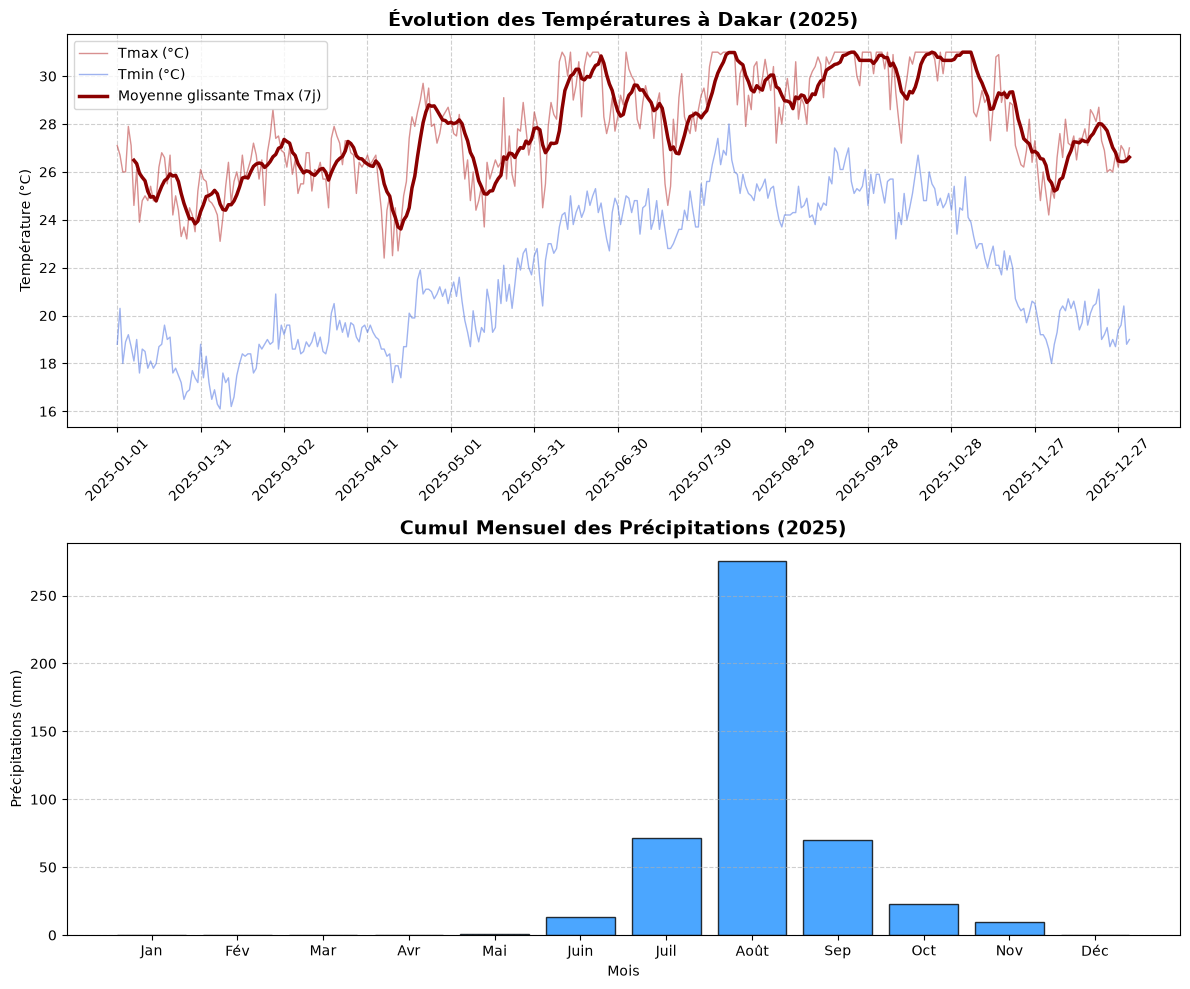

In [62]:
import matplotlib.pyplot as plt

# Calcul de la pluie mensuelle pour le graphique en barres
pluie_mensuelle = np.bincount(mois - 1, weights=pluie)

# Alignement des dates pour la moyenne glissante (à partir du 7ème jour)
dates_liss = dates[6:]

# Création d'une figure à deux sous-graphiques (2 lignes, 1 colonne)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

# --- Graphique 1 : Températures ---
ax1.plot(dates, tmax, label="Tmax (°C)", color="firebrick", alpha=0.5, linewidth=1)
ax1.plot(dates, tmin, label="Tmin (°C)", color="royalblue", alpha=0.5, linewidth=1)
ax1.plot(dates_liss, tmax_liss, label="Moyenne glissante Tmax (7j)", color="darkred", linewidth=2.5)

ax1.set_title("Évolution des Températures à Dakar (2025)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Température (°C)")
ax1.set_xticks(dates[::30])  # Une graduation tous les 30 jours
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper left")

# --- Graphique 2 : Cumul de pluie mensuel ---
ax2.bar(NOMS_MOIS, pluie_mensuelle, color="dodgerblue", edgecolor="black", alpha=0.8)

ax2.set_title("Cumul Mensuel des Précipitations (2025)", fontsize=14, fontweight="bold")
ax2.set_xlabel("Mois")
ax2.set_ylabel("Précipitations (mm)")
ax2.grid(True, axis='y', linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
